In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
 

np.random.seed(42)
num_samples = 1000
fiyat = np.random.uniform(100, 1000, num_samples)
puan = np.random.uniform(1, 5, num_samples)
mensei = np.random.choice(['A', 'B', 'C', 'D'], num_samples)
urun_ad = [f"Urun_{i}" for i in range(num_samples)]
data = pd.DataFrame({'urun_ad': urun_ad, 'fiyat': fiyat, 'puan': puan, 'mensei': mensei})
 

In [25]:
X = data[['fiyat', 'puan']].values
X_scaled = StandardScaler().fit_transform(X) 
 
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
data['cluster'] = kmeans.fit_predict(X_scaled)
 
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

c:\Users\kerim\miniconda3\envs\ml\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


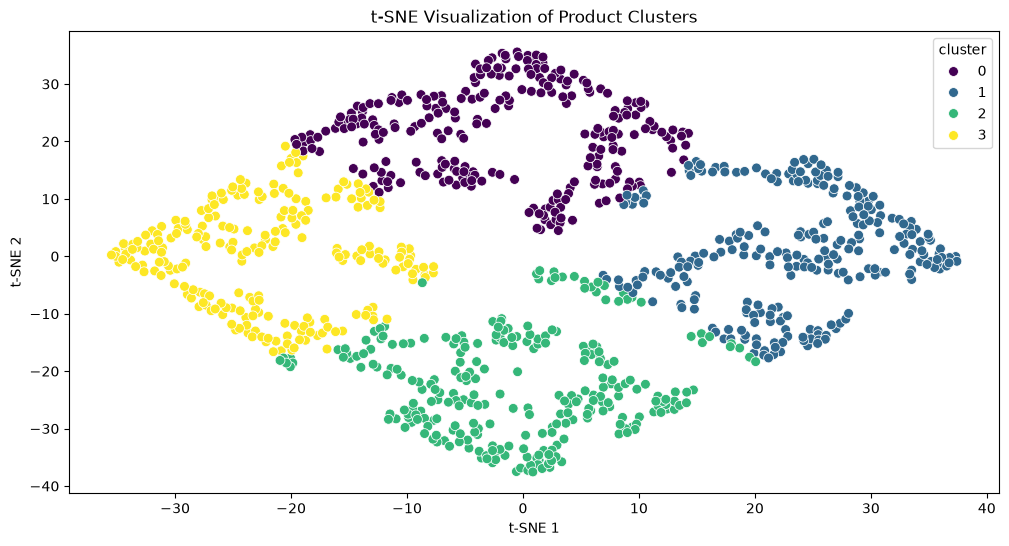

In [26]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=data['cluster'],
                palette='viridis', s=50)
plt.title('t-SNE Visualization of Product Clusters')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

Text(0.5, 1.0, 'Hierarchical Clustering Dendrogram')

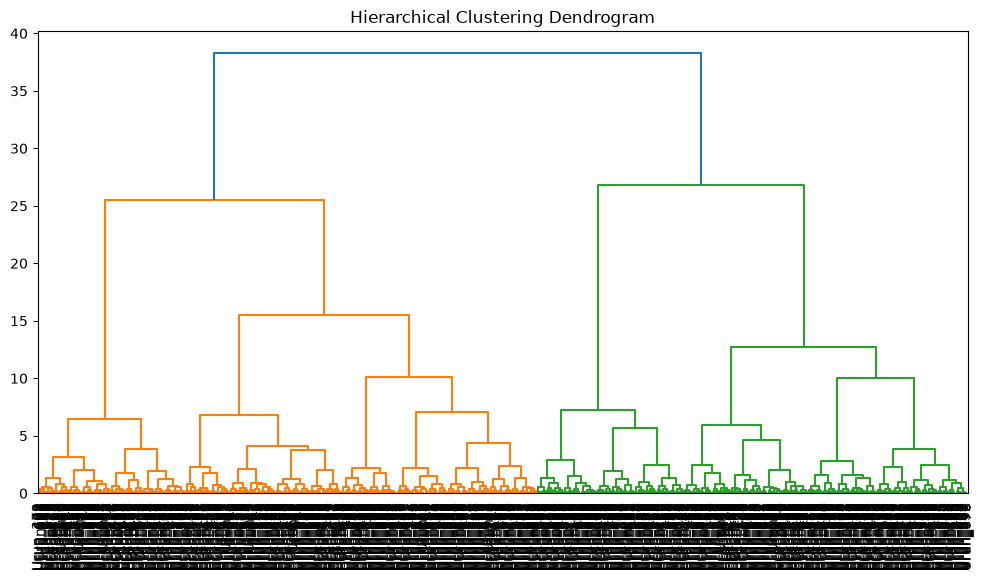

In [27]:
linkage_matrix = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix, labels=data['urun_ad'].values, leaf_rotation=90, leaf_font_size=10)
plt.title('Hierarchical Clustering Dendrogram')